# Processing Culture: 10 — Greed, Toxicity, and Repair (R Edition)

**Companion to Lecture 06: Greed, Toxicity, and Repair**

This R notebook explores resource-frame language and phrase cues in fictional voice-message transcripts. The examples and labels are AI-generated for this teaching exercise; they are synthetic, not collected observations or independently human-annotated data. No audio or personal information is used. The phrase audit cannot identify a speaker, authenticate a voice, or establish intent or consent.

[Lecture 06](../../lectures/lecture_06_greed_toxicity_and_repair.md) · [Python notebook](../python/10_greed_toxicity_and_repair.ipynb) · [FTC guidance on family-emergency scams](https://consumer.ftc.gov/consumer-alerts/2023/03/scammers-use-ai-enhance-their-family-emergency-schemes)

## Questions and limits

1. Which words frame a resource as a fixed contest, and which suggest cooperation can create shared gains?
2. What can simple lexical cues flag in a high-stakes message, and what can they not tell us?
3. How do sample construction and illustrative labels limit our conclusions?

A zero-sum or positive-sum label describes the sentence's framing, not the world itself. A larger total surplus does not guarantee fair distribution. All plots describe this small synthetic set only.

In [1]:
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(stringr)
  library(ggplot2)
})

theme_mlg <- function() {
  theme_minimal(base_size = 11) +
    theme(
      plot.title = element_text(face = "bold", color = "#1A202C"),
      plot.subtitle = element_text(color = "#4A5568"),
      axis.title = element_text(face = "bold", color = "#2D3748"),
      panel.grid.minor = element_blank(),
      panel.grid.major = element_line(color = "#E2E8F0")
    )
}

cat("Environment ready: local, synthetic examples only.\n")

Warning message:
“package ‘dplyr’ was built under R version 4.2.3”
Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”


Environment ready: local, synthetic examples only.


## 1. Synthetic examples of resource frames

`zero_sum` marks wording that presents one party's gain as another's loss or treats the resource as fixed. `positive_sum` marks wording that emphasizes cooperation or expanding shared benefit. These are illustrative labels for the wording, not judgments about a real policy or resource.

In [2]:
frames <- tibble::tribble(
  ~id, ~frame, ~text,
  "z01", "zero_sum", "If they get more seats, our community loses influence.",
  "z02", "zero_sum", "Every raise for workers means less profit for owners.",
  "z03", "zero_sum", "There is only one home available; if I get it, someone else cannot.",
  "z04", "zero_sum", "Their gain is our loss.",
  "z05", "zero_sum", "We have to protect our share before someone takes it.",
  "z06", "zero_sum", "A limited grant has one winner, so applicants compete.",
  "z07", "zero_sum", "More funding for them means less for us.",
  "z08", "zero_sum", "A fixed number of seats must be divided among candidates.",
  "p01", "positive_sum", "We can build more homes and share the benefits.",
  "p02", "positive_sum", "A public library gives everyone more ways to learn.",
  "p03", "positive_sum", "Cooperative childcare frees time for families and creates paid work.",
  "p04", "positive_sum", "Cleaner transit can reduce costs and improve access.",
  "p05", "positive_sum", "We can expand the grant pool and fund more projects.",
  "p06", "positive_sum", "Better tools can raise output while we share gains.",
  "p07", "positive_sum", "A joint project lets both teams contribute and benefit.",
  "p08", "positive_sum", "Preventing illness helps workers, families, and employers."
) %>%
  mutate(frame = factor(frame, levels = c("zero_sum", "positive_sum")))

stopifnot(!anyDuplicated(frames$id), nrow(frames) == 16)
frames

id,frame,text
<chr>,<fct>,<chr>
z01,zero_sum,"If they get more seats, our community loses influence."
z02,zero_sum,Every raise for workers means less profit for owners.
z03,zero_sum,"There is only one home available; if I get it, someone else cannot."
z04,zero_sum,Their gain is our loss.
z05,zero_sum,We have to protect our share before someone takes it.
z06,zero_sum,"A limited grant has one winner, so applicants compete."
z07,zero_sum,More funding for them means less for us.
z08,zero_sum,A fixed number of seats must be divided among candidates.
p01,positive_sum,We can build more homes and share the benefits.


## 2. Token frequencies

We lowercase and tokenize words while retaining apostrophes and hyphens. Negation is retained because removing words such as `not` or `never` can reverse a statement's meaning. Frequency differences suggest what to inspect; they are not estimates of public opinion or policy effects.

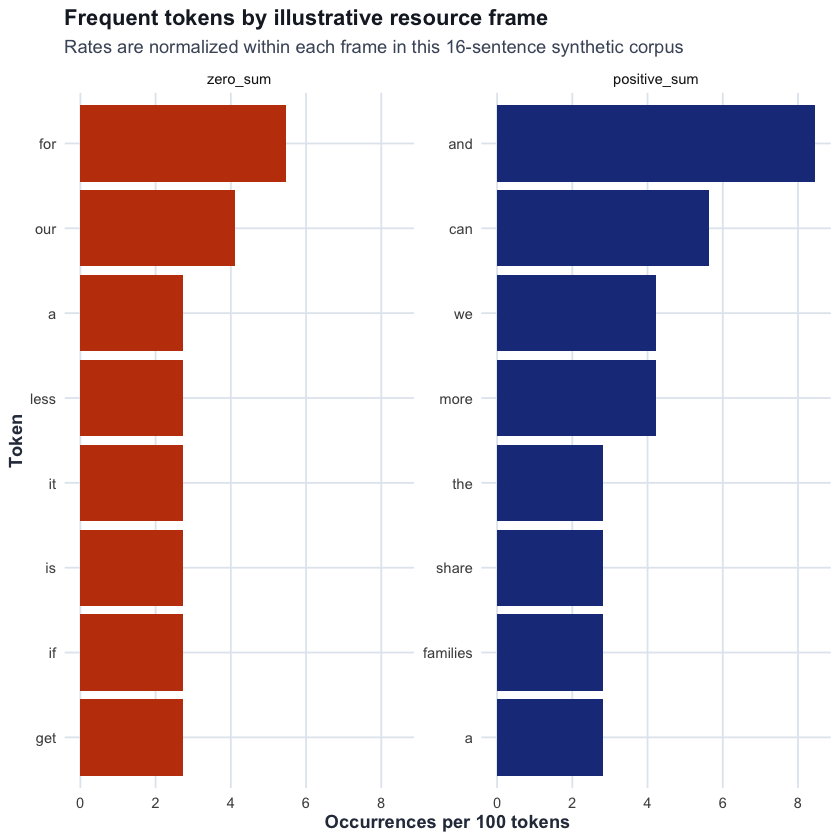

In [3]:
tokens <- frames %>%
  mutate(token = str_extract_all(str_to_lower(text), "[a-z0-9]+(?:['-][a-z0-9]+)*")) %>%
  unnest(token)

token_counts <- tokens %>%
  count(frame, token, name = "count") %>%
  group_by(frame) %>%
  mutate(per_100_tokens = 100 * count / sum(count)) %>%
  ungroup()

top_terms <- token_counts %>%
  group_by(frame) %>%
  slice_max(per_100_tokens, n = 8, with_ties = FALSE) %>%
  ungroup()

ggplot(top_terms, aes(x = per_100_tokens, y = reorder(token, per_100_tokens), fill = frame)) +
  geom_col(show.legend = FALSE) +
  facet_wrap(~frame, scales = "free_y") +
  scale_fill_manual(values = c(zero_sum = "#C2410C", positive_sum = "#1E3A8A")) +
  labs(
    title = "Frequent tokens by illustrative resource frame",
    subtitle = "Rates are normalized within each frame in this 16-sentence synthetic corpus",
    x = "Occurrences per 100 tokens", y = "Token"
  ) +
  theme_mlg()

## 3. TF–IDF contrasts and lexical similarity

We calculate term frequency–inverse document frequency (TF–IDF) and cosine similarity directly. These describe lexical overlap, not agreement, truth, shared intent, or common authorship. With this small crafted corpus, they are a demonstration of a method rather than a meaningful estimate.

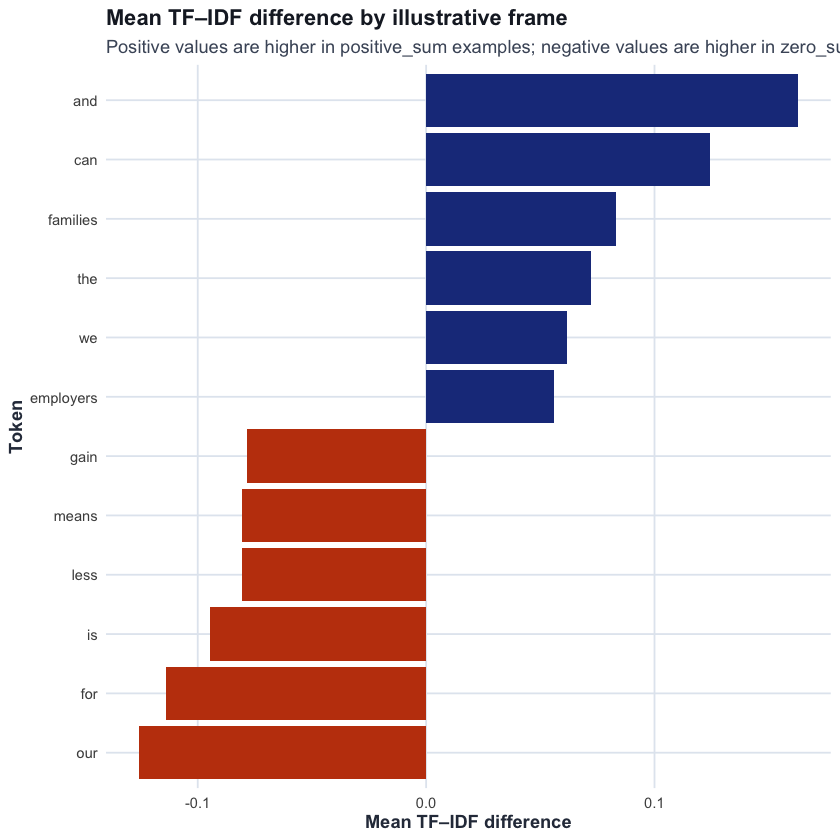

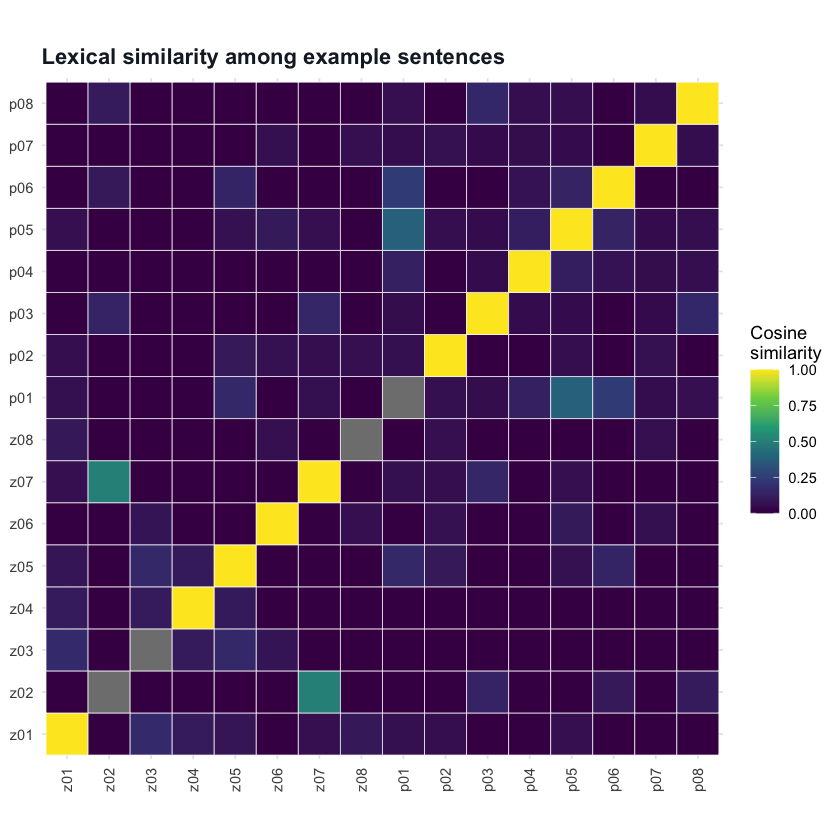

In [4]:
vocabulary <- sort(unique(tokens$token))
count_matrix <- matrix(
  0, nrow = nrow(frames), ncol = length(vocabulary),
  dimnames = list(frames$id, vocabulary)
)
for (i in seq_len(nrow(frames))) {
  word_counts <- table(tokens$token[tokens$id == frames$id[i]])
  count_matrix[i, names(word_counts)] <- as.numeric(word_counts)
}

tf <- count_matrix / rowSums(count_matrix)
idf <- log((1 + nrow(count_matrix)) / (1 + colSums(count_matrix > 0))) + 1
tfidf <- sweep(tf, 2, idf, `*`)
mean_tfidf <- rowsum(tfidf, group = frames$frame) / as.vector(table(frames$frame))
contrast <- mean_tfidf["positive_sum", ] - mean_tfidf["zero_sum", ]

contrast_data <- tibble(token = names(contrast), difference = as.numeric(contrast)) %>%
  slice_max(difference, n = 6, with_ties = FALSE) %>%
  bind_rows(
    tibble(token = names(contrast), difference = as.numeric(contrast)) %>%
      slice_min(difference, n = 6, with_ties = FALSE)
  ) %>%
  distinct(token, .keep_all = TRUE) %>%
  arrange(difference) %>%
  mutate(token = factor(token, levels = token))

p_contrast <- ggplot(contrast_data, aes(x = difference, y = token, fill = difference > 0)) +
  geom_col(show.legend = FALSE) +
  scale_fill_manual(values = c(`FALSE` = "#C2410C", `TRUE` = "#1E3A8A")) +
  labs(
    title = "Mean TF–IDF difference by illustrative frame",
    subtitle = "Positive values are higher in positive_sum examples; negative values are higher in zero_sum examples",
    x = "Mean TF–IDF difference", y = "Token"
  ) + theme_mlg()

row_norms <- sqrt(rowSums(tfidf^2))
normalized <- tfidf / row_norms
cosine <- normalized %*% t(normalized)
similarity_data <- as.data.frame(as.table(cosine)) %>%
  setNames(c("sentence_a", "sentence_b", "similarity"))

p_similarity <- ggplot(similarity_data, aes(sentence_a, sentence_b, fill = similarity)) +
  geom_tile(color = "white", linewidth = 0.2) +
  scale_fill_viridis_c(limits = c(0, 1), name = "Cosine\nsimilarity") +
  coord_equal() +
  labs(title = "Lexical similarity among example sentences", x = NULL, y = NULL) +
  theme_mlg() +
  theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1))

p_contrast
p_similarity

## 4. Phrase-cue audit for fictional voice-message transcripts

The labels below are illustrative decisions to verify through another channel before acting. A flagged message is not a finding of fraud; an unflagged message is not proof of safety. We include an urgent but harmless message (a likely false positive) and a vague high-stakes request with none of the listed phrases (a likely false negative).

In [5]:
messages <- tibble::tribble(
  ~message_id, ~transcript, ~review_label,
  "m01", "Mom, I lost my phone. I am at the station. Send $400 right now and do not call.", "verify",
  "m02", "This is your manager. I need your one-time code to unlock payroll. Keep this between us.", "verify",
  "m03", "Hi, it is Alex. I was in an accident. Buy gift cards and text me the numbers.", "verify",
  "m04", "I need you to wire money before the bank closes. Do not tell anyone.", "verify",
  "m05", "It is me. Can you make a payment to the new account? I will explain when I see you.", "verify",
  "m06", "Urgent: our meeting moved to 3 PM. Can you confirm the calendar invite?", "ordinary",
  "m07", "Here is my voice note about the weekend. Call me when you have time.", "ordinary",
  "m08", "Reminder: please send the invoice tomorrow. No rush.", "ordinary"
)

risk_cues <- c(
  "send money", "send $", "wire money", "gift cards", "one-time code",
  "verification code", "do not call", "do not tell",
  "keep this between us", "right now", "urgent"
)

find_risk_cues <- function(text) {
  risk_cues[vapply(risk_cues, function(cue) str_detect(str_to_lower(text), fixed(cue)), logical(1))]
}

messages <- messages %>%
  mutate(
    matched_cues = lapply(transcript, find_risk_cues),
    cue_count = lengths(matched_cues),
    baseline_flag = if_else(cue_count > 0, "verify", "ordinary")
  )
messages %>%
  mutate(matched_cues = vapply(matched_cues, paste, collapse = ", ", FUN.VALUE = character(1))) %>%
  select(message_id, review_label, baseline_flag, matched_cues)

message_id,review_label,baseline_flag,matched_cues
<chr>,<chr>,<chr>,<chr>
m01,verify,verify,"send $, do not call, right now"
m02,verify,verify,"one-time code, keep this between us"
m03,verify,verify,gift cards
m04,verify,verify,"wire money, do not tell"
m05,verify,ordinary,
m06,ordinary,verify,urgent
m07,ordinary,ordinary,
m08,ordinary,ordinary,


                         Phrase baseline
Illustrative review label ordinary verify
                 ordinary        2      1
                 verify          1      4

Synthetic-corpus counts — true negatives: 2, false positives: 1, false negatives: 1, true positives: 4


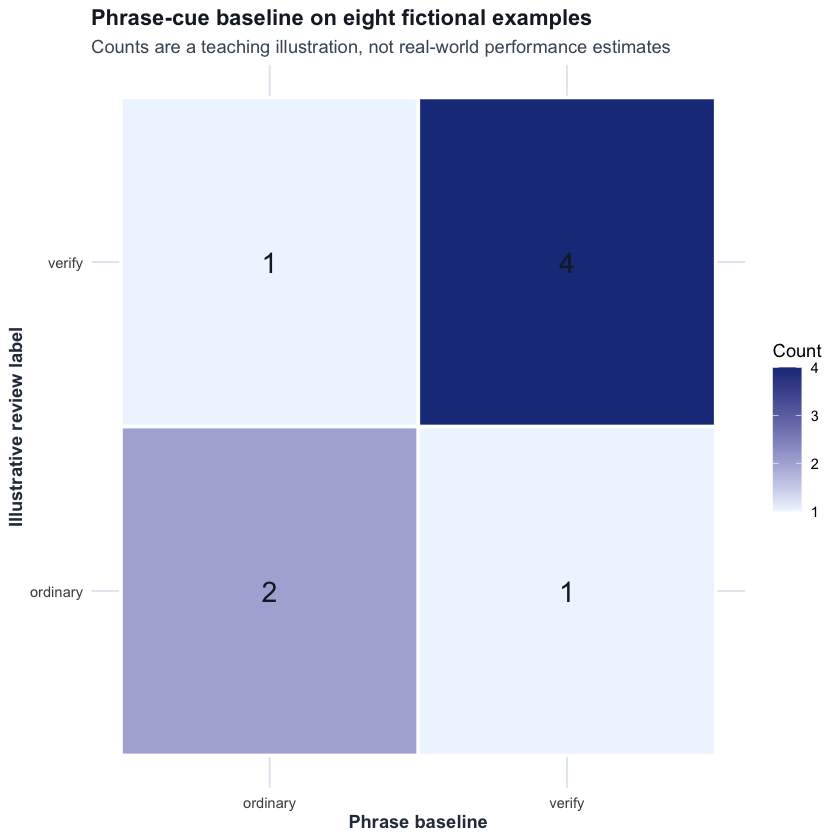

In [6]:
class_order <- c("ordinary", "verify")
confusion <- table(
  factor(messages$review_label, levels = class_order),
  factor(messages$baseline_flag, levels = class_order),
  dnn = c("Illustrative review label", "Phrase baseline")
)
confusion

tn <- confusion["ordinary", "ordinary"]
fp <- confusion["ordinary", "verify"]
fn <- confusion["verify", "ordinary"]
tp <- confusion["verify", "verify"]
stopifnot(identical(as.integer(c(tn, fp, fn, tp)), c(2L, 1L, 1L, 4L)))
cat(sprintf("Synthetic-corpus counts — true negatives: %d, false positives: %d, false negatives: %d, true positives: %d\n", tn, fp, fn, tp))

confusion_data <- as.data.frame(confusion) %>%
  setNames(c("review_label", "baseline_flag", "count"))
ggplot(confusion_data, aes(baseline_flag, review_label, fill = count)) +
  geom_tile(color = "white", linewidth = 1) +
  geom_text(aes(label = count), size = 6, color = "#1A202C") +
  scale_fill_gradient(low = "#EFF6FF", high = "#1E3A8A") +
  labs(
    title = "Phrase-cue baseline on eight fictional examples",
    subtitle = "Counts are a teaching illustration, not real-world performance estimates",
    x = "Phrase baseline", y = "Illustrative review label", fill = "Count"
  ) + theme_mlg()

### Interpret the misses, not just the score

- `m06` is a false positive because *urgent* appears in a routine scheduling message.
- `m05` is a false negative because its risky payment request uses wording absent from the cue list.
- The denominator is eight fictional examples. These counts say almost nothing about real-world performance.
- Even a perfect text classifier would classify only a transcript under its annotation scheme. It would not establish who spoke, whether the audio was edited, whether the person consented, or what they intended.

For an actual urgent request: pause; verify on a separately obtained, trusted channel; do not send money or share passwords or one-time codes based on voice alone; preserve the original message and context; and report suspected impersonation through the relevant service. No listening test or detector can guarantee that a voice is genuine.

## 5. Consent, data ethics, and exercises

Voice synthesis can support augmentative communication, a person's chosen voice when speech changes, translation, and creative work. Ethical use needs consent specifying purpose, audience, duration, review rights, disclosure, compensation where appropriate, and how use can be limited or revoked. Permission to record or model a voice is not blanket permission to generate arbitrary statements in that voice. Avoid uploading private recordings to untrusted services.

1. Draft a codebook for zero-sum, positive-sum, mixed, and uncertain framing. Have multiple annotators label a properly licensed, non-sensitive sample and report disagreements.
2. Add negation, quotation, sarcasm, and conditional statements. Explain why lexical methods can fail in each case.
3. Test the same codebook in another domain or time period; inspect underrepresented categories without inferring motives from lexical differences.
4. Design a voice-message verification protocol that does not depend on voice similarity, public personal facts, or a code phrase as sole proof.
5. Distinguish expanding shared benefits from redistributing fixed resources. Ask who owns gains and who bears externalized costs.

### Takeaway

Computational linguistics can make patterns in wording visible. It cannot turn wording into transparent access to a person's interior life. A familiar-sounding voice still requires provenance and context; a growing surplus still raises a distributional question.